In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ecommerce_sales_cleaned.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (106, 11)


,Order_ID,Product,Category,Region,Quantity,Unit_Price,Sales,Profit,Discount_Percent,Customer_Age,Customer_Rating
0,1001,Laptop,Electronics,North,2.0,1200,2400.0,480.0,5,22,4.5
1,1002,Smartphone,Electronics,South,3.0,700,2100.0,315.0,10,25,4.2
2,1003,Headphones,Electronics,East,5.0,80,400.0,120.0,5,21,4.0
3,1004,Office Chair,Furniture,West,2.0,180,360.0,72.0,0,34,4.3
4,1005,Desk,Furniture,North,1.0,300,300.0,75.0,10,29,4.1


In [2]:
print("Descriptive Statistics:")
display(df.describe())

print("\nCategorical Column Summary:")
display(df.describe(include="object"))

Descriptive Statistics:


,Order_ID,Quantity,Unit_Price,Sales,Profit,Discount_Percent,Customer_Age,Customer_Rating
count,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000
mean,1053.500000,3.339623,285.528302,1490.292453,162.708019,5.754717,32.509434,4.368396
std,30.743563,2.476121,539.235229,9677.861927,485.278487,3.637925,18.096169,0.296754
min,1001.000000,1.000000,-300.000000,-300.000000,-75.000000,0.000000,19.000000,3.700000
25%,1027.250000,2.000000,65.000000,240.000000,68.025000,5.000000,25.000000,4.100000
50%,1053.500000,3.000000,177.500000,351.000000,83.400000,5.000000,29.500000,4.375000
75%,1079.750000,4.000000,288.750000,540.000000,133.750000,10.000000,36.750000,4.600000
max,1106.000000,20.000000,5000.000000,100000.000000,5000.000000,10.000000,200.000000,4.900000



Categorical Column Summary:


C:\Users\Nithya Rajah\AppData\Local\Temp\ipykernel_35740\496773630.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Product,Category,Region
count,106,106,106
unique,20,3,4
top,Laptop,Electronics,North
freq,6,63,27


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types and Non-Null Counts:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Column Names:
['Order_ID', 'Product', 'Category', 'Region', 'Quantity', 'Unit_Price', 'Sales', 'Profit', 'Discount_Percent', 'Customer_Age', 'Customer_Rating']

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 106 entries, 0 to 105
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          106 non-null    int64  
 1   Product           106 non-null    str    
 2   Category          106 non-null    str    
 3   Region            106 non-null    str    
 4   Quantity          106 non-null    float64
 5   Unit_Price        106 non-null    int64  
 6   Sales             106 non-null    float64
 7   Profit            106 non-null    float64
 8   Discount_Percent  106 non-null    int64  
 9   Customer_Age      106 non-null    int64  
 10  Customer_Rating   106 non-null    float64
dtypes: float64(4), int64(4), str(3)
memory usage: 9.2 KB

Missing Values:
Order_ID            0
Produ

In [4]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Order_ID,Quantity,Unit_Price,Sales,Profit,Discount_Percent,Customer_Age,Customer_Rating
Order_ID,1.00,0.11,0.08,0.15,0.12,0.01,0.19,0.31
Quantity,0.11,1.00,0.41,0.65,0.63,-0.12,-0.26,-0.02
Unit_Price,0.08,0.41,1.00,0.88,0.93,0.09,-0.03,0.33
Sales,0.15,0.65,0.88,1.00,0.99,-0.01,-0.03,0.17
Profit,0.12,0.63,0.93,0.99,1.00,0.02,-0.05,0.22
Discount_Percent,0.01,-0.12,0.09,-0.01,0.02,1.00,-0.24,0.28
Customer_Age,0.19,-0.26,-0.03,-0.03,-0.05,-0.24,1.00,-0.08
Customer_Rating,0.31,-0.02,0.33,0.17,0.22,0.28,-0.08,1.00


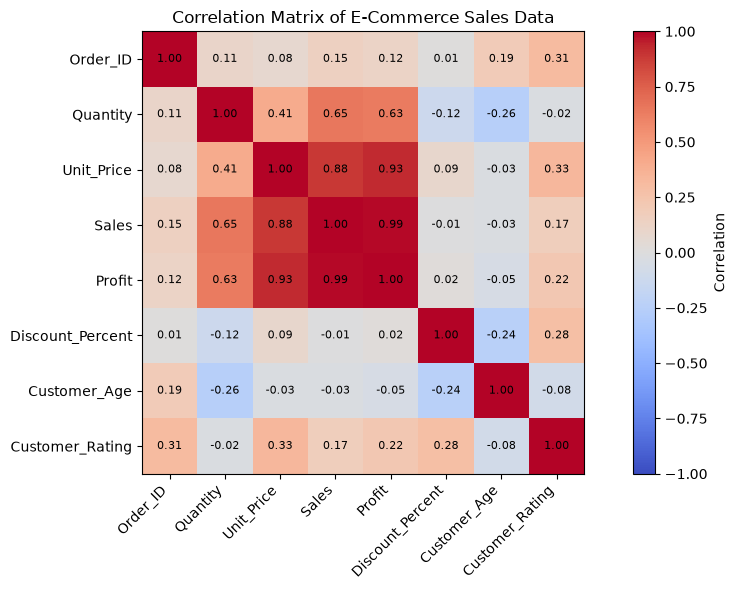

In [5]:
plt.figure(figsize=(10, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of E-Commerce Sales Data")

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

plt.tight_layout()
plt.show()

In [6]:
# Identify outliers using the IQR method

numeric_df = df.select_dtypes(include="number")

for col in numeric_df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower Limit:", round(lower_limit, 2))
    print("Upper Limit:", round(upper_limit, 2))
    print("Number of Outliers:", len(outliers))


Column: Order_ID
Lower Limit: 948.5
Upper Limit: 1158.5
Number of Outliers: 0

Column: Quantity
Lower Limit: -1.0
Upper Limit: 7.0
Number of Outliers: 4

Column: Unit_Price
Lower Limit: -270.62
Upper Limit: 624.38
Number of Outliers: 13

Column: Sales
Lower Limit: -210.0
Upper Limit: 990.0
Number of Outliers: 14

Column: Profit
Lower Limit: -30.56
Upper Limit: 232.34
Number of Outliers: 11

Column: Discount_Percent
Lower Limit: -2.5
Upper Limit: 17.5
Number of Outliers: 0

Column: Customer_Age
Lower Limit: 7.38
Upper Limit: 54.38
Number of Outliers: 1

Column: Customer_Rating
Lower Limit: 3.35
Upper Limit: 5.35
Number of Outliers: 0


In [8]:
print("Sales by Product Category:")

category_sales = df.groupby("Category")["Sales"].sum().sort_values(
    ascending=False
)

display(category_sales)

Sales by Product Category:


Category
Electronics    143928.0
Furniture       11702.0
Accessories      2341.0
Name: Sales, dtype: float64

In [9]:
print("Sales by Region:")

region_sales = df.groupby("Region")["Sales"].sum().sort_values(
    ascending=False
)

display(region_sales)

Sales by Region:


Region
North    117753.0
South     16763.0
East      14127.0
West       9328.0
Name: Sales, dtype: float64

In [10]:
print("Average Sales by Discount:")

discount_sales = df.groupby("Discount_Percent")["Sales"].mean().sort_index()

display(discount_sales)

Average Sales by Discount:


Discount_Percent
0      340.476190
5     2595.770833
10     708.756757
Name: Sales, dtype: float64

In [11]:
# Total profit by product
product_profit = df.groupby("Product")["Profit"].sum().sort_values(
    ascending=False
)

print("Profit by Product:")
display(product_profit)

print("\nMost Profitable Product:")
print(product_profit.idxmax(), "-", product_profit.max())

print("\nLeast Profitable Product:")
print(product_profit.idxmin(), "-", product_profit.min())

Profit by Product:


Product
Laptop            7158.00
Smartphone        1569.75
Tablet             912.00
Smartwatch         693.75
Headphones         666.60
Desk               617.50
Office Chair       514.00
Webcam             513.90
Monitor            509.00
External SSD       506.25
Office Table       490.00
Backpack           481.50
Earbuds            395.10
Printer            360.00
Keyboard           357.30
Mouse              337.50
Filing Cabinet     331.00
Bookshelf          308.00
Desk Lamp          305.10
USB Hub            220.80
Name: Profit, dtype: float64


Most Profitable Product:
Laptop - 7158.0

Least Profitable Product:
USB Hub - 220.8


In [12]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Average Sales per Order:", round(df["Sales"].mean(), 2))
print("Average Profit per Order:", round(df["Profit"].mean(), 2))
print("Average Customer Rating:", round(df["Customer_Rating"].mean(), 2))
print("Average Discount (%):", round(df["Discount_Percent"].mean(), 2))

Total Sales: 157971.0
Total Profit: 17247.05
Average Sales per Order: 1490.29
Average Profit per Order: 162.71
Average Customer Rating: 4.37
Average Discount (%): 5.75


In [13]:
print("========== EDA SUMMARY ==========")

print(f"Total Records: {len(df)}")
print(f"Total Columns: {len(df.columns)}")
print(f"Total Sales: {df['Sales'].sum():.2f}")
print(f"Total Profit: {df['Profit'].sum():.2f}")
print(f"Average Customer Rating: {df['Customer_Rating'].mean():.2f}")

print("\nSales by Category:")
display(df.groupby("Category")["Sales"].sum().sort_values(ascending=False))

print("\nSales by Region:")
display(df.groupby("Region")["Sales"].sum().sort_values(ascending=False))

print("\nProfit by Product:")
display(df.groupby("Product")["Profit"].sum().sort_values(ascending=False))

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

========== EDA SUMMARY ==========
Total Records: 106
Total Columns: 11
Total Sales: 157971.00
Total Profit: 17247.05
Average Customer Rating: 4.37

Sales by Category:


Category
Electronics    143928.0
Furniture       11702.0
Accessories      2341.0
Name: Sales, dtype: float64


Sales by Region:


Region
North    117753.0
South     16763.0
East      14127.0
West       9328.0
Name: Sales, dtype: float64


Profit by Product:


Product
Laptop            7158.00
Smartphone        1569.75
Tablet             912.00
Smartwatch         693.75
Headphones         666.60
Desk               617.50
Office Chair       514.00
Webcam             513.90
Monitor            509.00
External SSD       506.25
Office Table       490.00
Backpack           481.50
Earbuds            395.10
Printer            360.00
Keyboard           357.30
Mouse              337.50
Filing Cabinet     331.00
Bookshelf          308.00
Desk Lamp          305.10
USB Hub            220.80
Name: Profit, dtype: float64


Missing Values: 0
Duplicate Rows: 0
